In [1]:
%matplotlib inline
import os
import re
import itertools
from itertools import combinations
import glob
import pickle
import argparse
import gzip

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import multiprocess as mp
import numpy as np
import pandas as pd
import bioframe as bf
from matplotlib import gridspec
from matplotlib.gridspec import GridSpec
import matplotlib.colors as colors
from matplotlib.colors import ListedColormap
from collections import OrderedDict
import plotly.express as px
import plotly.graph_objects as go
from matplotlib.cm import ScalarMappable
from scipy.ndimage import gaussian_filter

import timeit

In [2]:
#define a function to read list
def read_excel_files(pattern):
    files = glob.glob(pattern)
    file_dict = {}
    for i, file in enumerate(files):
        df = pd.read_excel(file, header=0)
        # Extract text within brackets for 'BinaryID' column
        df['BinaryID'] = df['BinaryID'].apply(lambda x: re.search(r'\((.*?)\)', x).group(1))
        file_dict[i] = df
    return file_dict

In [3]:
#process the data to extract useful information
def process_list(cell_list):
    cell_df = pd.DataFrame()
    for j in range(len(cell_list)):
        example = cell_list[j]
        #get the DAPI row of individual cells
        dapi_rows = example[example['BinaryID'] == 'DAPI']
        for i in range(len(dapi_rows)):
            # Calculate the radius of DAPI
            radius = (dapi_rows.iloc[i]['FillArea [µm²]'] / np.pi)**0.5
            # Define the center coordinates of DAPI
            center_x = dapi_rows.iloc[i]['CentreX [µm]']
            center_y = dapi_rows.iloc[i]['CentreY [µm]']
            #extract the fractions within the DAPI area
            mask = ((example['CentreX [µm]'] - center_x)**2 + (example['CentreY [µm]'] - center_y)**2) <= (radius + 1)**2 
            df = example[mask].copy()
            #get the 'FillArea' and 'Distance' information
            df['distance'] = np.sqrt((df['CentreX [µm]'] - center_x)**2 + (df['CentreY [µm]'] - center_y)**2)/radius   
            df1 = df.groupby("BinaryID").agg({'FillArea [µm²]': "sum", 'distance': "mean"})
            
            #organized together
            organized = {
                'Purple_field': df1.loc['Combined_RedhavingGreen', 'FillArea [µm²]'] if 'Combined_RedhavingGreen' in df1.index else np.nan,
                'Red_field': df1.loc['Combined_RedinDAPI', 'FillArea [µm²]'] if 'Combined_RedinDAPI' in df1.index else np.nan,
                'Green_field': df1.loc['EGFP', 'FillArea [µm²]'] if 'EGFP' in df1.index else np.nan,
                'Blue_field': df1.loc['DAPI', 'FillArea [µm²]'] if 'DAPI' in df1.index else np.nan,
                'Purple_distance': df1.loc['Combined_RedhavingGreen', 'distance'] if 'Combined_RedhavingGreen' in df1.index else np.nan,
                'Red_distance': df1.loc['Combined_RedinDAPI', 'distance'] if 'Combined_RedinDAPI' in df1.index else np.nan,
                'Green_distance': df1.loc['EGFP', 'distance'] if 'EGFP' in df1.index else np.nan
            }
            
            organized_df = pd.DataFrame([organized])
            cell_df = pd.concat([cell_df, organized_df], ignore_index=True)
    
    cell_df.dropna(inplace=True)
    cell_df.reset_index(drop=True, inplace=True)
    
    return cell_df

In [4]:
# read sample list and processing it

# Define file patterns for different lists
patterns = {
    'mHep': "/home/xiangru.huo-umw/scHiC/scripts/image_K27ac/mHep*.xlsx",
    'iHep': "/home/xiangru.huo-umw/scHiC/scripts/image_K27ac/iHep*.xlsx",
    'HB': "/home/xiangru.huo-umw/scHiC/scripts/image_K27ac/HB*.xlsx",
    'DE': "/home/xiangru.huo-umw/scHiC/scripts/image_K27ac/DE*.xlsx",
    'H1': "/home/xiangru.huo-umw/scHiC/scripts/image_K27ac/H1*.xlsx",
    'hela': "/home/xiangru.huo-umw/scHiC/scripts/image_K27ac/hela*.xlsx"
}

# Initialize a dictionary to store all lists
all_lists = {key: read_excel_files(pattern) for key, pattern in patterns.items()}

# Apply the processing function to each list
organized_results = {key: process_list(all_lists[key]) for key in ['mHep', 'iHep', 'HB','DE','H1','hela']}

In [11]:
len(organized_results['HB'])

61

In [6]:
#calculate K9me3 blured regions ratio of K27ac
purpleVSred = []
stage_label = []
purple_area = []
red_area = []
red_distance = []
purple_distance = []
green_distance = []

for stage in ['hela','H1','DE','HB','iHep','mHep']:
    df = organized_results[stage].copy()
    purpleVSred_t = df['Purple_field']/df['Red_field']
    purpleVSred.extend(purpleVSred_t)
    
    purple_area.extend(df['Purple_field'])
    red_area.extend(df['Red_field'])
    
    red_distance.extend(df['Red_distance'])
    purple_distance.extend(df['Purple_distance'])
    green_distance.extend(df['Green_distance'])
       
    stage_label.extend([stage] * len(purpleVSred_t))
    
Summary_df = pd.DataFrame({'stage':stage_label,
                            'K9me3inK27ac_area/K27ac_area': purpleVSred,
                            'K27ac_area': red_area,
                            'K9me3inK27ac_area': purple_area,
                            'K9me3_distance': green_distance,
                            'K27ac_distance': red_distance,
                            'K9me3inK27ac_distance': purple_distance})

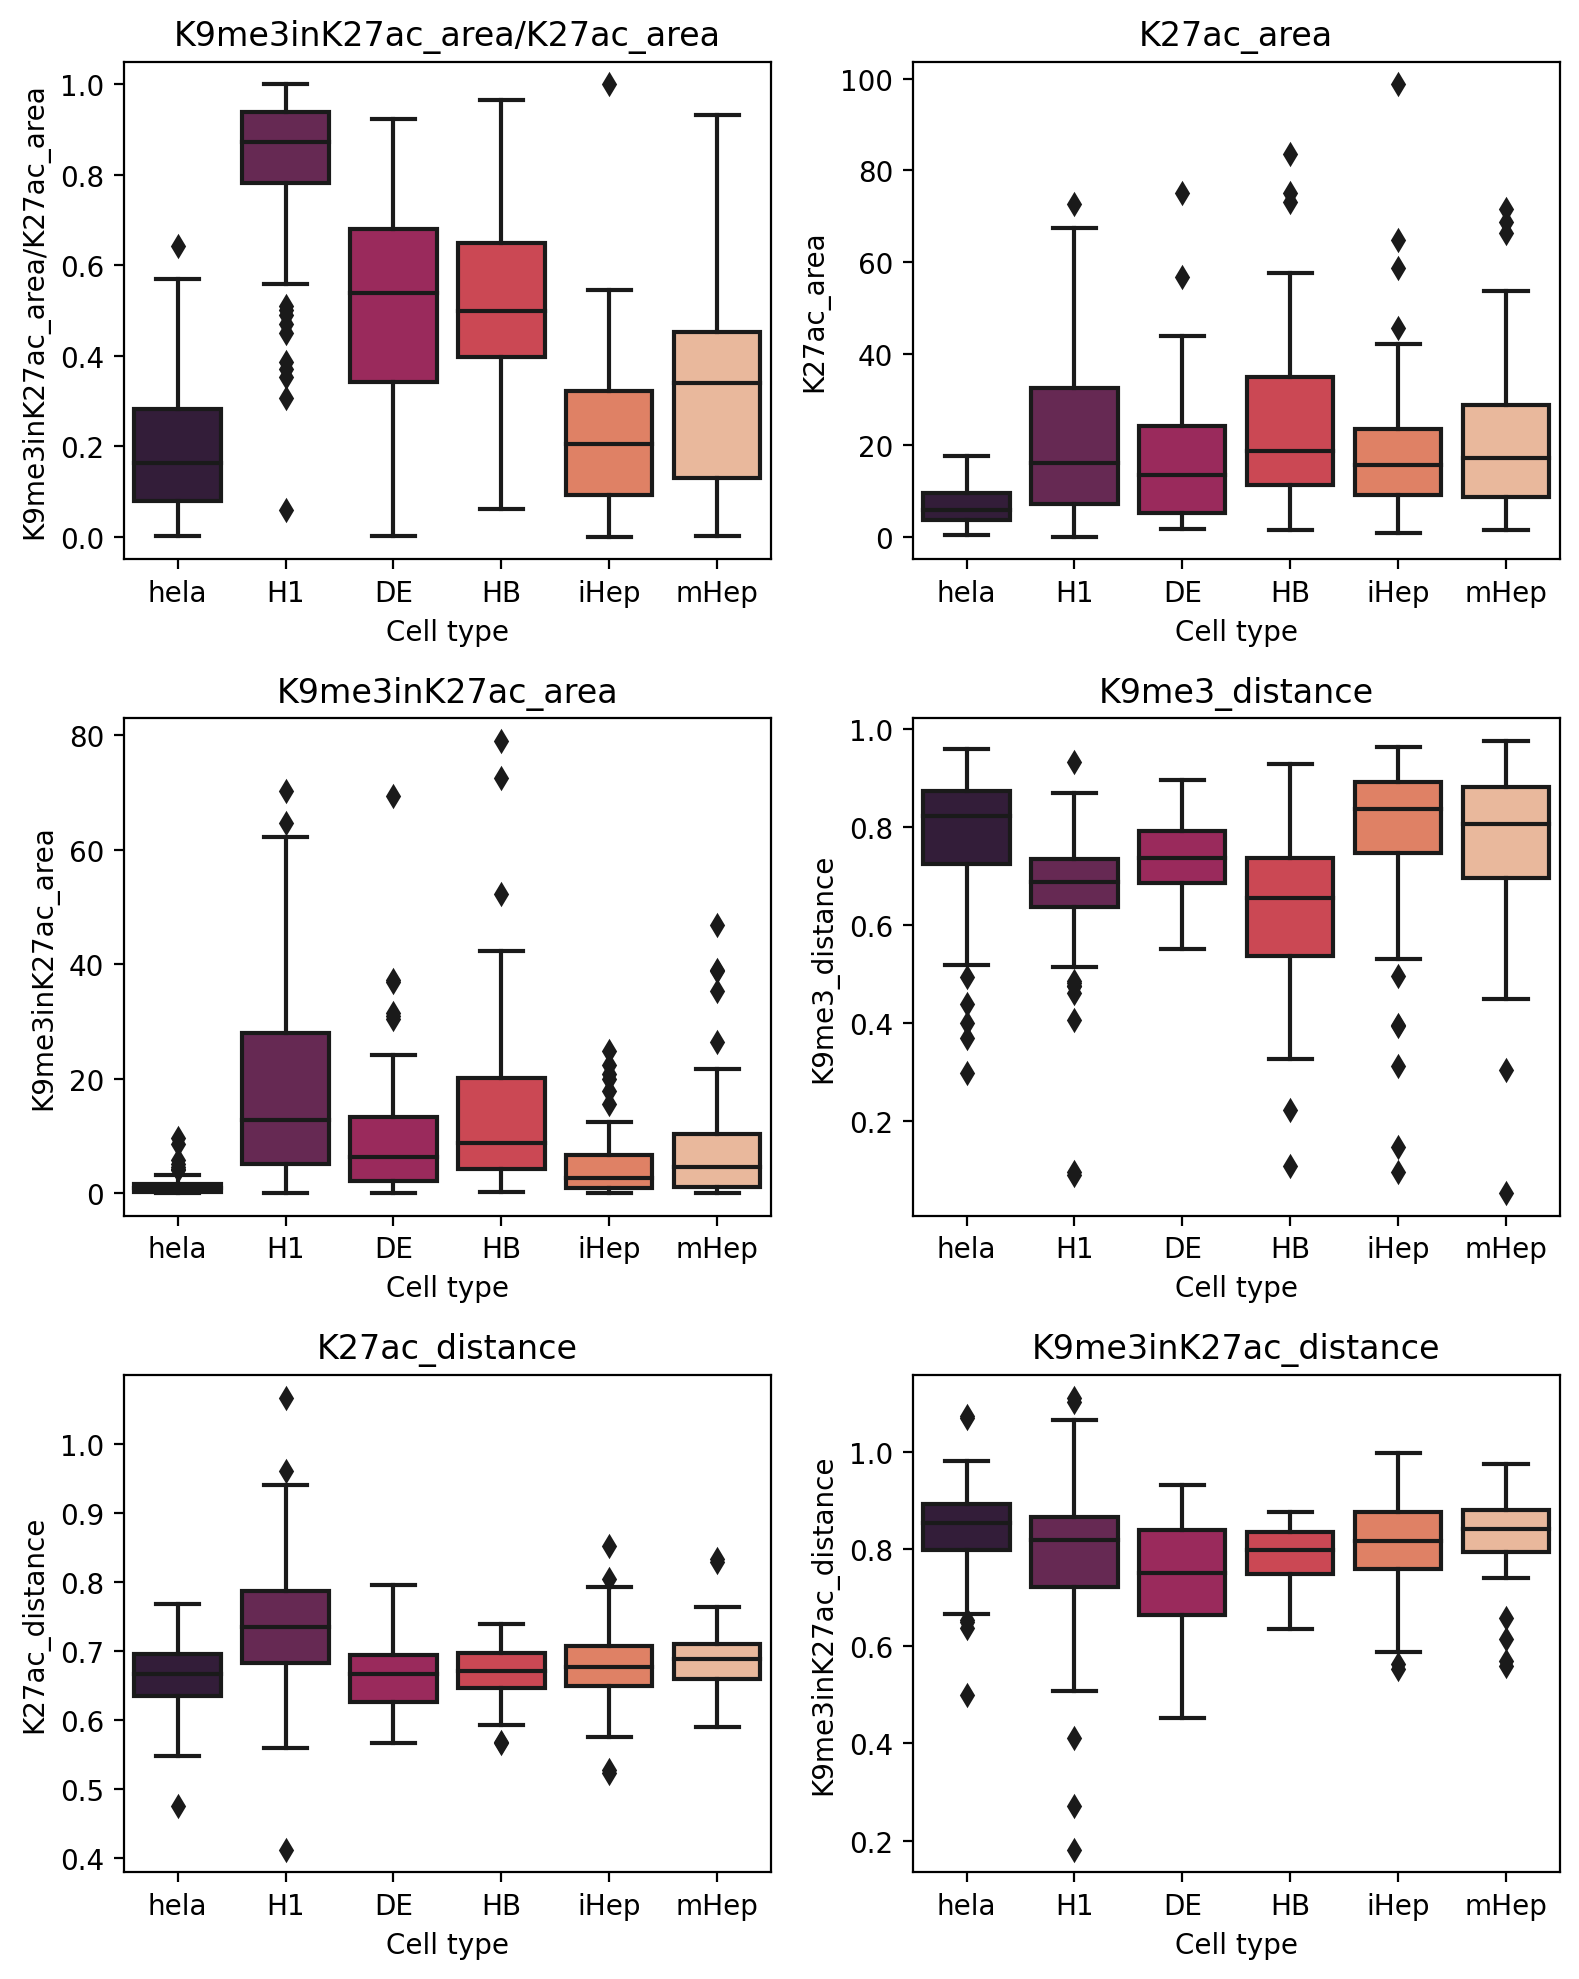

In [ ]:
# Set up the subplots
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(8, 10), dpi=200)

# List of columns to plot
columns_to_plot = [
    'K9me3inK27ac_area/K27ac_area',
    'K27ac_area',
    'K9me3inK27ac_area',
    'K9me3_distance',
    'K27ac_distance',
    'K9me3inK27ac_distance'
]

# Plot each boxplot
for i, col in enumerate(columns_to_plot):
    row = i // 2
    col_idx = i % 2
    sns.boxplot(data=Summary_df, x='stage', y=col, palette='rocket', ax=axes[row, col_idx])
    axes[row, col_idx].set_title(f'{col}')
    axes[row, col_idx].set_xlabel('Cell type')
    axes[row, col_idx].set_ylabel(col)

# Remove any empty subplots
for j in range(i+1, 6):
    fig.delaxes(axes.flatten()[j])

# Adjust layout
plt.tight_layout()
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Image_K27ac_organized.pdf", 
            format="pdf", bbox_inches="tight")
plt.show()

In [17]:
#add statistic significance
#pip install statannot
from statannot import add_stat_annotation

Note: you may need to restart the kernel to use updated packages.


p-value annotation legend:
ns: 5.00e-02 < p <= 1.00e+00
*: 1.00e-02 < p <= 5.00e-02
**: 1.00e-03 < p <= 1.00e-02
***: 1.00e-04 < p <= 1.00e-03
****: p <= 1.00e-04

H1 v.s. DE: t-test independent samples with Bonferroni correction, P_val=1.439e-19 stat=1.054e+01
iHep v.s. mHep: t-test independent samples with Bonferroni correction, P_val=1.198e-01 stat=-2.421e+00
H1 v.s. HB: t-test independent samples with Bonferroni correction, P_val=6.605e-22 stat=1.128e+01
HB v.s. mHep: t-test independent samples with Bonferroni correction, P_val=5.619e-05 stat=4.704e+00
H1 v.s. iHep: t-test independent samples with Bonferroni correction, P_val=6.338e-58 stat=2.370e+01
DE v.s. mHep: t-test independent samples with Bonferroni correction, P_val=1.161e-03 stat=3.924e+00
H1 v.s. mHep: t-test independent samples with Bonferroni correction, P_val=1.172e-33 stat=1.568e+01
p-value annotation legend:
ns: 5.00e-02 < p <= 1.00e+00
*: 1.00e-02 < p <= 5.00e-02
**: 1.00e-03 < p <= 1.00e-02
***: 1.00e-04 < p <= 1.0

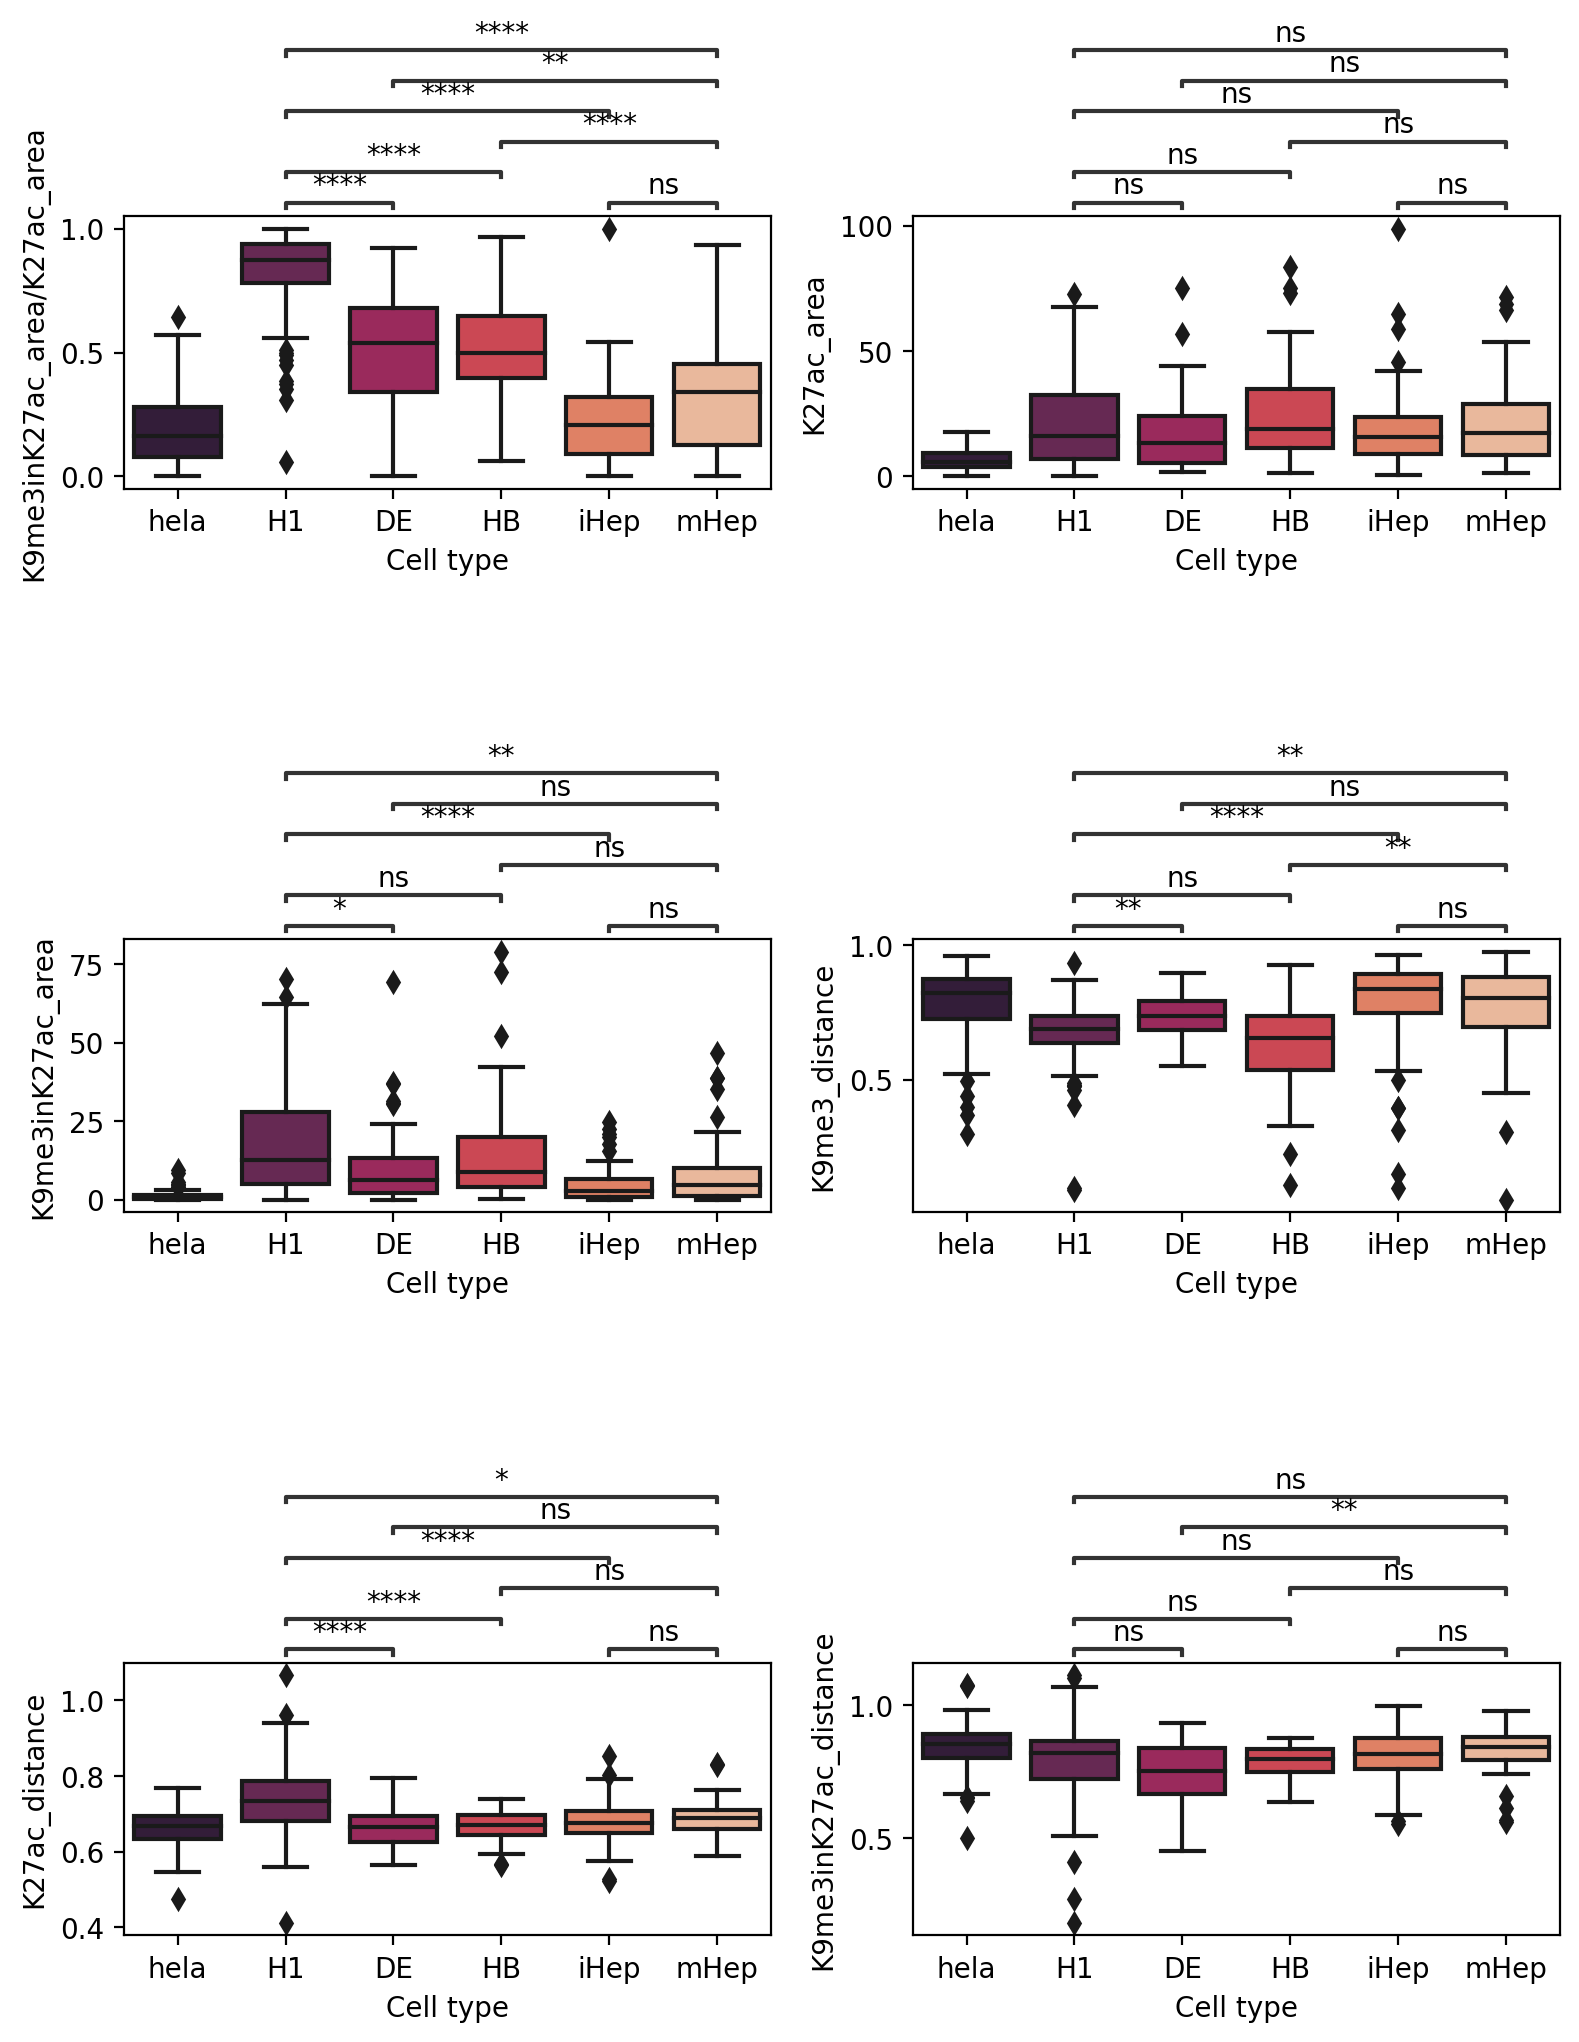

In [23]:
# Set up the subplots
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(8, 11), dpi=200)

# List of columns to plot
columns_to_plot = [
    'K9me3inK27ac_area/K27ac_area',
    'K27ac_area',
    'K9me3inK27ac_area',
    'K9me3_distance',
    'K27ac_distance',
    'K9me3inK27ac_distance'
]

# Define pairs for comparisons
comparisons = [
    ("H1", "DE"),
    ("H1", "HB"),
    ("H1", "iHep"),
    ("H1", "mHep"),
     ("mHep", "DE"),
    ("mHep", "HB"),
    ("mHep", "iHep")
]

# Plot each boxplot and add statistical annotation
for i, col in enumerate(columns_to_plot):
    row = i // 2
    col_idx = i % 2
    ax = axes[row, col_idx]
    sns.boxplot(data=Summary_df, x='stage', y=col, palette='rocket', ax=ax)
#    ax.set_title(f'{col}')
    ax.set_xlabel('Cell type')
    ax.set_ylabel(col)
    
    # Add statistical annotations
    add_stat_annotation(
        ax, data=Summary_df, x='stage', y=col,
        box_pairs=comparisons,
        test='t-test_ind', text_format='star', loc='outside', verbose=2
    )

# Remove any empty subplots
for j in range(i+1, 6):
    fig.delaxes(axes.flatten()[j])

# Adjust layout
plt.tight_layout()
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Image_K27ac_organized_2.pdf", 
            format="pdf", bbox_inches="tight")
plt.show()